**Computational Tools for Data Science (02807), Fall 2026, DTU — Final Project**

# Clustering-Based Selection of Representative Wind Power Days

**Problem.** Capacity-expansion and storage-sizing models become expensive when all 8,760 hours of a year are used.
We compress five years of hourly Danish (DK1) wind production and day-ahead prices into $k$ *weighted representative days*
and measure how much information is lost (energy, duration curve, ramps, value of wind).

**Course topics used**
1. *General clustering*: k-means (baseline) and hierarchical clustering on a precomputed distance matrix; Davies–Bouldin index.
2. *Graph clustering*: k-nearest-neighbour similarity graph, spectral clustering (own implementation) and Louvain; modularity.

**Method not taught in the course**: Dynamic Time Warping (DTW) with a Sakoe–Chiba band (own implementation).

**Notebook outline**

| Part | Content |
|---|---|
| 0 | Setup, settings and instructions |
| 1 | Download the data from Energi Data Service (API, cached in `Data/`) |
| 2 | Preprocessing: hourly table, daily profiles, capacity proxy, train/test split |
| 3 | DTW: implementation, sanity checks, distance matrices |
| 4 | Representative days and evaluation metrics (incl. random baseline) |
| 5 | General clustering: k-means and hierarchical clustering |
| 6 | Graph clustering: kNN graph, spectral clustering, Louvain, modularity |
| 7 | Main experiment: error vs. number of representative days $k$ |
| 8 | Sensitivity: DTW radius and graph neighbourhood size |
| 9 | Interpretation of the representative days |
| 10 | Summary table and group contributions |

**How to run.** Install the packages listed in Part 0 and use *Run All*. The first run downloads about 45,000 hourly rows per dataset
into `Data/` (a few minutes, depending on the connection); later runs read the cached CSV files.
DTW matrices are cached in `Data/` as `.npy` files. Total runtime after the first download: a few minutes on a laptop.

### Part 0: Setup

Required packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn` (>= 1.2), `networkx` (>= 3.0), `requests`.
Optional: `tslearn` (only used to cross-check our DTW implementation).

```
pip install numpy pandas matplotlib scikit-learn networkx requests
```

In [1]:
   import os
   print(os.environ.get('CONDA_PREFIX'))
   import numpy as np
   a = np.random.rand(500, 500)
   print((a @ a).sum())

E:\conda_envs\02807
31197885.86411525


In [2]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import sklearn
import networkx as nx

from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score, pairwise_distances
from networkx.algorithms.community import louvain_communities
from networkx.algorithms.community.quality import modularity as nx_modularity

for m in [np, pd, sklearn, nx]:
    print(f"{m.__name__:10s}: {m.__version__}")

numpy     : 2.4.6
pandas    : 3.0.5
sklearn   : 1.9.1
networkx  : 3.6.1


In [3]:
# ---------------------------------------------------------------- settings ---
DATA_DIR = Path.cwd() / 'Data'      # assumes the notebook and the Data folder are in the same directory
DATA_DIR.mkdir(exist_ok=True)

PRICE_AREA   = 'DK1'                # bidding zone west of the Great Belt
START, END   = '2021-01-01', '2026-01-01'   # Danish local time, END exclusive
SPLIT_DATE   = '2025-10-01'         # Elspotprices ends here, DayAheadPrices (15 min) starts here
TRAIN_YEARS  = [2021, 2022, 2023, 2024]     # representative days are selected on these years
TEST_YEARS   = [2025]                       # out-of-sample evaluation

FEATURES     = ['wind', 'price']    # channels of a daily profile used for the distance
DTW_RADIUS   = 2                    # Sakoe-Chiba band (hours) for the main experiment
K_NN         = 10                   # neighbours in the similarity graph
K_LIST       = [4, 6, 8, 12, 16, 24, 32]    # numbers of representative days
N_RANDOM     = 50                   # repetitions of the random baseline
N_SEEDS      = 10                   # random seeds for the stochastic methods (k-means, spectral)
K_FIX        = 12                   # number of representative days for the detailed analysis
RANDOM_STATE = 42

### Part 1: Download the data

We use two public datasets from Energinet's **Energi Data Service** (https://www.energidataservice.dk):

- `ProductionConsumptionSettlement` (hourly, per price area, from 2005): offshore wind (<100 MW, >=100 MW), onshore wind (<50 kW, >=50 kW),
  solar, gross consumption, ...
- Day-ahead prices: `Elspotprices` (hourly, until 2025-09-30) and its successor `DayAheadPrices` (15 min, from 2025-10-01).

The API returns JSON records. We page through the results with `offset`/`limit`, download one extra day on each side
(the time filter of the API refers to one specific time column) and cut the exact period locally.
Every dataset is saved once as CSV in `Data/`, so the notebook can be rerun offline.

In [4]:
API_URL = 'https://api.energidataservice.dk/dataset/'

def fetch_dataset(name, start, end, columns, time_col, price_area=PRICE_AREA, page_size=50000):
    """Downloads one dataset from Energi Data Service.

    :param name: str, dataset name, e.g. 'ProductionConsumptionSettlement'
    :param start: str, first date (inclusive), 'YYYY-MM-DD'
    :param end: str, last date (exclusive), 'YYYY-MM-DD'
    :param columns: list of str, columns to download
    :param time_col: str, time column used for sorting
    :param price_area: str, bidding zone
    :param page_size: int, number of records per request

    :return: DataFrame with the downloaded records
    """
    records, offset = [], 0
    while True:
        params = {'start': start, 'end': end,
                  'filter': json.dumps({'PriceArea': [price_area]}),
                  'columns': ','.join(columns),
                  'sort': f'{time_col} asc',
                  'offset': offset, 'limit': page_size}
        r = requests.get(API_URL + name, params=params, timeout=120)
        r.raise_for_status()
        batch = r.json()['records']
        records.extend(batch)
        print(f"  {name}: {len(records)} records")
        if len(batch) < page_size:
            break
        offset += page_size
    return pd.DataFrame(records)


def load_or_download(filename, **kwargs):
    """Reads Data/<filename> if it exists, otherwise downloads it via fetch_dataset and caches it."""
    path = DATA_DIR / filename
    if path.exists():
        print(f"read cached {path.name}")
        return pd.read_csv(path)
    df = fetch_dataset(**kwargs)
    df.to_csv(path, index=False)
    return df

In [5]:
# one extra day on each side, the exact period is cut in Part 2
day = pd.Timedelta('1D')
s_ext = (pd.Timestamp(START) - day).strftime('%Y-%m-%d')
e_ext = (pd.Timestamp(END) + day).strftime('%Y-%m-%d')

WIND_COLS  = ['OffshoreWindLt100MW_MWh', 'OffshoreWindGe100MW_MWh',
              'OnshoreWindLt50kW_MWh', 'OnshoreWindGe50kW_MWh']
SOLAR_COLS = ['SolarPowerLt10kW_MWh', 'SolarPowerGe10Lt40kW_MWh', 'SolarPowerGe40kW_MWh']

prod = load_or_download(f'production_{PRICE_AREA}.csv',
                        name='ProductionConsumptionSettlement', start=s_ext, end=e_ext,
                        columns=['HourUTC', 'HourDK', 'PriceArea'] + WIND_COLS + SOLAR_COLS + ['GrossConsumptionMWh'],
                        time_col='HourUTC')

spot = load_or_download(f'elspot_{PRICE_AREA}.csv',
                        name='Elspotprices', start=s_ext, end=SPLIT_DATE,
                        columns=['HourUTC', 'HourDK', 'PriceArea', 'SpotPriceEUR'],
                        time_col='HourUTC')

dap = load_or_download(f'dayahead_{PRICE_AREA}.csv',
                       name='DayAheadPrices', start=SPLIT_DATE, end=e_ext,
                       columns=['TimeUTC', 'TimeDK', 'PriceArea', 'DayAheadPriceEUR'],
                       time_col='TimeUTC')

#sanity check
print(f'{prod.shape=}, {spot.shape=}, {dap.shape=}')

read cached production_DK1.csv
read cached elspot_DK1.csv
read cached dayahead_DK1.csv
prod.shape=(43872, 11), spot.shape=(41639, 4), dap.shape=(8932, 4)


### Part 2: Preprocessing

1. **Hourly table.** Total wind = sum of the four wind columns. The 15-min day-ahead prices are averaged to hourly values
   and appended to the hourly Elspot prices (the same harmonisation as in our 46765 preprocessing). All series are joined on `HourUTC`.
2. **Days in Danish local time.** The day-ahead market is settled per Danish delivery day, so days are cut on `HourDK`.
   Days with 23 or 25 hours (daylight saving time changes) and days with missing values are removed and counted.
3. **Capacity proxy.** Installed capacity grows over five years. Without a capacity series, we divide the production of each
   calendar year by its 99.9 % quantile (robust maximum). This gives a capacity-factor proxy `cf` in $[0, \approx 1]$, so that
   "more turbines" is not mistaken for "more wind". *Assumption: capacity is roughly constant within a year.*
4. **Relative price.** Price levels differ strongly between years (2022 energy crisis). We use `price_rel = price / annual mean price`.
   With this scale the value factor (capture price / average price) of wind is $VF = \sum_t cf_t\,price\_rel_t / \sum_t cf_t$.
5. **Daily profiles and split.** Each day becomes an array of shape (24, channels). Days of 2021–2024 are used to select
   representative days (train), days of 2025 for out-of-sample evaluation (test).

In [6]:
def build_hourly_table(prod, spot, dap):
    """Joins wind, solar, consumption and day-ahead price into one hourly table indexed by HourUTC.

    :return: DataFrame with columns HourDK, wind_MWh, solar_MWh, load_MWh, price
    """
    # Step 1: production and consumption
    p = prod.copy()
    p['HourUTC'] = pd.to_datetime(p['HourUTC'])
    p['wind_MWh'] = p[WIND_COLS].sum(axis=1, min_count=1)     # NaN only if all wind columns are missing
    p['solar_MWh'] = p[SOLAR_COLS].sum(axis=1, min_count=1)
    p = p.rename(columns={'GrossConsumptionMWh': 'load_MWh'})
    p = p.drop_duplicates('HourUTC').set_index('HourUTC')[['HourDK', 'wind_MWh', 'solar_MWh', 'load_MWh']]

    # Step 2: prices, hourly Elspot + 15-min day-ahead averaged to hours
    s = spot.copy()
    s['HourUTC'] = pd.to_datetime(s['HourUTC'])
    s = s.set_index('HourUTC')['SpotPriceEUR']
    d = dap.copy()
    d['HourUTC'] = pd.to_datetime(d['TimeUTC']).dt.floor('h')
    d = d.groupby('HourUTC')['DayAheadPriceEUR'].mean()
    price = pd.concat([s, d]).rename('price')
    price = price[~price.index.duplicated(keep='first')]

    # Step 3: join on UTC (unique), keep Danish local time for cutting days
    df = p.join(price, how='left').sort_index()
    df['HourDK'] = pd.to_datetime(df['HourDK'])
    return df

hourly = build_hourly_table(prod, spot, dap)
hourly = hourly[(hourly['HourDK'] >= START) & (hourly['HourDK'] < END)]

#sanity check
print(f'{hourly.shape=}')
print(hourly.isna().sum())
hourly.head()

hourly.shape=(43824, 5)
HourDK       0
wind_MWh     0
solar_MWh    0
load_MWh     0
price        0
dtype: int64


,HourDK,wind_MWh,solar_MWh,load_MWh,price
HourUTC,,,,,
2020-12-31 23:00:00,2021-01-01 00:00:00,167.671783,0.108759,2049.782322,50.869999
2021-01-01 00:00:00,2021-01-01 01:00:00,134.187454,0.102916,1997.949899,48.189999
2021-01-01 01:00:00,2021-01-01 02:00:00,109.574683,0.102080,1925.228978,44.680000
2021-01-01 02:00:00,2021-01-01 03:00:00,86.089584,0.099609,1864.332901,42.919998
2021-01-01 03:00:00,2021-01-01 04:00:00,74.722602,0.098817,1839.519202,40.389999


In [7]:
def daily_profiles(hourly):
    """Cuts the hourly table into complete days in Danish local time.

    :return: DataFrame (one row per day) with 24-hour arrays per variable, plus a log of removed days
    """
    h = hourly.copy()
    h['date'] = h['HourDK'].dt.normalize()

    # Step 1: capacity proxy per calendar year (robust maximum) and relative price
    year = h['HourDK'].dt.year
    h['cf'] = h['wind_MWh'] / h.groupby(year)['wind_MWh'].transform(lambda x: x.quantile(0.999))
    h['price_rel'] = h['price'] / h.groupby(year)['price'].transform('mean')

    # Step 2: keep days with exactly 24 hours and no missing values
    g = h.groupby('date')
    n_hours = g.size()
    n_missing = g[['wind_MWh', 'price']].apply(lambda x: x.isna().any(axis=1).sum())
    keep = n_hours[(n_hours == 24) & (n_missing == 0)].index
    log = {'days total': len(n_hours),
           'removed (23/25 h, DST)': int((n_hours != 24).sum()),
           'removed (missing values)': int(((n_hours == 24) & (n_missing > 0)).sum()),
           'kept': len(keep)}

    # Step 3: one row per day with 24-hour arrays
    h = h[h['date'].isin(keep)]
    days = pd.DataFrame({c: h.groupby('date')[c].apply(np.array)
                         for c in ['cf', 'price_rel', 'wind_MWh', 'price', 'load_MWh', 'solar_MWh']})
    days['year'] = days.index.year
    days['month'] = days.index.month
    return days, log

days, log = daily_profiles(hourly)
print(log)
days.head()

{'days total': 1826, 'removed (23/25 h, DST)': 10, 'removed (missing values)': 0, 'kept': 1816}


,cf,price_rel,wind_MWh,price,load_MWh,solar_MWh,year,month
date,,,,,,,,
2021-01-01,"[0.041276688830096324, 0.033033666634658884, 0...","[0.5771643523607856, 0.546757423036354, 0.5069...","[167.671783, 134.187454, 109.574683, 86.089584...","[50.869999, 48.189999, 44.68, 42.919998, 40.38...","[2049.782322, 1997.949899, 1925.228978, 1864.3...","[0.108759, 0.102916, 0.10208, 0.099609, 0.0988...",2021,1
2021-01-02,"[0.008349693249725901, 0.005058482832043512, 0...","[0.529738619309993, 0.481405228072997, 0.46620...","[33.917642, 20.548277, 11.744432, 25.510945, 4...","[46.689999, 42.43, 41.09, 40.0, 37.549999, 39....","[1925.171419, 1875.394326, 1854.224127, 1846.3...","[0.103247, 0.101961, 0.10509700000000001, 0.10...",2021,1
2021-01-03,"[0.12975364580471938, 0.13982630479822225, 0.1...","[0.523158037894205, 0.47187469798623494, 0.422...","[527.077771, 567.9943450000001, 699.8235219999...","[46.110001, 41.59, 37.209999, 35.18, 24.65, 23...","[1976.610318, 1905.241337, 1872.684526, 1984.4...","[0.104143, 0.097945, 0.092454, 0.089592, 0.093...",2021,1
2021-01-04,"[0.4034001841461138, 0.45319208455423526, 0.38...","[0.27978913326137417, 0.2728681417334516, 0.27...","[1638.668945, 1840.930729, 1557.487051, 1437.5...","[24.66, 24.049999, 23.879999, 24.030001, 24.58...","[2386.759803, 2365.869849, 2276.945901, 2314.1...","[0.104462, 0.11268, 0.120249, 0.09926199999999...",2021,1
2021-01-05,"[0.5495823677395941, 0.5711574645465762, 0.560...","[0.31552860974086305, 0.3114441195382747, 0.30...","[2232.481774, 2320.1228869999995, 2275.264054,...","[27.809999, 27.450001, 27.08, 27.139999, 27.79...","[2457.77724, 2286.954502, 2246.658623, 2238.62...","[0.105041, 0.10516700000000001, 0.104796, 0.10...",2021,1


In [8]:
# daily arrays: shape (n_days, 24)
CF    = np.stack(days['cf'].values)
PREL  = np.stack(days['price_rel'].values)

train = days['year'].isin(TRAIN_YEARS).values
test  = days['year'].isin(TEST_YEARS).values

# channels for the distance: each channel scaled by its training standard deviation,
# so that wind and price get the same weight in the distance
CHANNELS = {'wind': CF, 'price': PREL}
def feature_array(features):
    """Stacks the chosen channels to shape (n_days, 24, n_channels), each scaled by its training std."""
    return np.stack([CHANNELS[f] / CHANNELS[f][train].std() for f in features], axis=2)

X = feature_array(FEATURES)

#sanity check
print(f'{X.shape=}, train days = {train.sum()}, test days = {test.sum()}')
print(f'correlation cf vs price_rel (hourly, train): {np.corrcoef(CF[train].ravel(), PREL[train].ravel())[0, 1]:.3f}')

X.shape=(1816, 24, 2), train days = 1453, test days = 363
correlation cf vs price_rel (hourly, train): -0.399


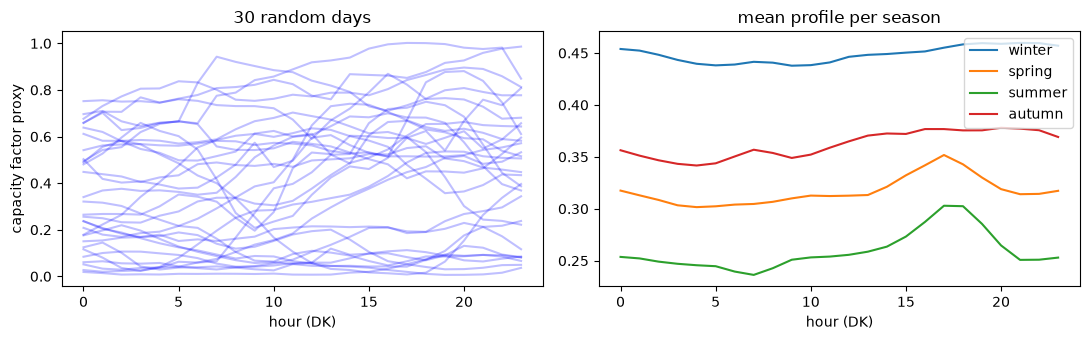

In [9]:
# lets have a look at the data: daily profiles of a few random days and the average profile per season
rng = np.random.default_rng(RANDOM_STATE)
fig, axs = plt.subplots(ncols=2, figsize=(11, 3.5))
for i in rng.choice(len(days), 30, replace=False):
    axs[0].plot(CF[i], color='b', alpha=0.25)
axs[0].set_title('30 random days'); axs[0].set_xlabel('hour (DK)'); axs[0].set_ylabel('capacity factor proxy')

season = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring',
          6: 'summer', 7: 'summer', 8: 'summer', 9: 'autumn', 10: 'autumn', 11: 'autumn'}
s = days['month'].map(season).values
for name in ['winter', 'spring', 'summer', 'autumn']:
    axs[1].plot(CF[s == name].mean(axis=0), label=name)
axs[1].set_title('mean profile per season'); axs[1].set_xlabel('hour (DK)'); axs[1].legend()
plt.tight_layout()
plt.show()

### Part 3: Dynamic Time Warping (method not taught in the course)

DTW compares two sequences while allowing a local time alignment. For daily profiles $x, y$ of length $T=24$
(each entry is a vector over the channels) the accumulated cost is computed by dynamic programming:

$$C(i,j) = \lVert x_i - y_j \rVert^2 + \min\{C(i-1,j),\; C(i,j-1),\; C(i-1,j-1)\},\qquad C(0,0)=0,$$

and $\mathrm{DTW}(x,y)=\sqrt{C(T,T)}$. The **Sakoe–Chiba band** only allows cells with $|i-j| \le r$, i.e. a time shift of at most
$r$ hours. For $r=0$ DTW equals the Euclidean distance, which gives a direct control experiment.

Why: two days with the same weather front (low → ramp up → high) but a ramp at 14:00 instead of 16:00 are far apart in
Euclidean distance. DTW treats them as similar, which should keep ramp shapes inside a cluster.

Implementation: `dtw_distance` is the straightforward double loop (reference). `dtw_one_to_many` vectorises the same
recursion over many sequences at once with NumPy, which makes the full distance matrix (~1.6 million pairs) feasible without numba.
DTW is not a metric and has no natural "mean curve", which is why it is combined with medoids, hierarchical clustering and graphs below.

In [10]:
def dtw_distance(x, y, radius):
    """DTW distance between two sequences with a Sakoe-Chiba band (reference implementation).

    :param x: nd-array, shape (T, c)
    :param y: nd-array, shape (T, c)
    :param radius: int, maximal time shift |i - j|

    :return: float, DTW distance
    """
    T = len(x)
    C = np.full((T + 1, T + 1), np.inf)
    C[0, 0] = 0.0
    for i in range(1, T + 1):
        for j in range(max(1, i - radius), min(T, i + radius) + 1):
            cost = np.sum((x[i - 1] - y[j - 1]) ** 2)
            C[i, j] = cost + min(C[i - 1, j], C[i, j - 1], C[i - 1, j - 1])
    return np.sqrt(C[T, T])


def dtw_one_to_many(x, Y, radius):
    """Same recursion as dtw_distance, vectorised over many sequences.

    :param x: nd-array, shape (T, c)
    :param Y: nd-array, shape (n, T, c)

    :return: nd-array, shape (n,), DTW distances between x and every Y[k]
    """
    n, T, _ = Y.shape
    C = np.full((n, T + 1, T + 1), np.inf)
    C[:, 0, 0] = 0.0
    for i in range(1, T + 1):
        for j in range(max(1, i - radius), min(T, i + radius) + 1):
            cost = ((Y[:, j - 1, :] - x[i - 1]) ** 2).sum(axis=1)
            C[:, i, j] = cost + np.minimum(np.minimum(C[:, i - 1, j], C[:, i, j - 1]), C[:, i - 1, j - 1])
    return np.sqrt(C[:, T, T])


def dtw_matrix(X, radius):
    """Symmetric matrix of pairwise DTW distances.

    :param X: nd-array, shape (n, T, c)
    :return: nd-array, shape (n, n)
    """
    n = len(X)
    D = np.zeros((n, n))
    for a in range(n - 1):
        D[a, a + 1:] = dtw_one_to_many(X[a], X[a + 1:], radius)
    return D + D.T

In [11]:
# sanity checks of our DTW implementation

# 1) radius 0 is the Euclidean distance
x, y = X[0], X[1]
assert np.isclose(dtw_distance(x, y, 0), np.linalg.norm(x - y))

# 2) the vectorised version gives the same values as the reference loop
ref = np.array([dtw_distance(X[0], X[k], 3) for k in range(1, 21)])
assert np.allclose(ref, dtw_one_to_many(X[0], X[1:21], 3))

# 3) toy example: a ramp shifted by 2 hours
t = np.arange(24)
ramp      = (1 / (1 + np.exp(-(t - 12)))).reshape(-1, 1)
ramp_late = (1 / (1 + np.exp(-(t - 14)))).reshape(-1, 1)
for r in [0, 1, 2, 3]:
    print(f'radius {r}: DTW(ramp, ramp shifted 2 h) = {dtw_distance(ramp, ramp_late, r):.3f}')

# 4) optional cross-check with tslearn (same squared-cost definition)
try:
    from tslearn.metrics import dtw as ts_dtw
    print('tslearn:', ts_dtw(X[0], X[1], global_constraint='sakoe_chiba', sakoe_chiba_radius=3),
          ' ours:', dtw_distance(X[0], X[1], 3))
except ImportError:
    print('tslearn not installed, cross-check skipped')

radius 0: DTW(ramp, ramp shifted 2 h) = 0.791
radius 1: DTW(ramp, ramp shifted 2 h) = 0.405
radius 2: DTW(ramp, ramp shifted 2 h) = 0.000
radius 3: DTW(ramp, ramp shifted 2 h) = 0.000
tslearn not installed, cross-check skipped


In [12]:
def distance_matrix(features, radius):
    """Pairwise distances between all days (train + test), cached in Data/.

    radius = None -> Euclidean distance on the flattened profiles
    radius = r    -> DTW with Sakoe-Chiba band r
    """
    Xf = feature_array(features)
    if radius is None:
        return pairwise_distances(Xf.reshape(len(Xf), -1))
    path = DATA_DIR / f"dtw_{PRICE_AREA}_{'-'.join(features)}_r{radius}_n{len(Xf)}.npy"
    if path.exists():
        return np.load(path)
    t0 = time.time()
    D = dtw_matrix(Xf, radius)
    print(f'DTW matrix r={radius}: {time.time() - t0:.1f} s')
    np.save(path, D)
    return D

D_euc = distance_matrix(FEATURES, None)
D_dtw = distance_matrix(FEATURES, DTW_RADIUS)

#sanity check: DTW can only be smaller than or equal to the Euclidean distance
assert np.all(D_dtw <= D_euc + 1e-9)
print(f'{D_dtw.shape=}, mean ratio DTW/Euclid = {np.mean(D_dtw[D_euc > 0] / D_euc[D_euc > 0]):.3f}')

D_dtw.shape=(1816, 1816), mean ratio DTW/Euclid = 0.970


### Part 4: Representative days and evaluation

**Representative days.** For any partition of the training days, the representative of a cluster is its **medoid**
(the clustroid from the lecture: the member with the smallest sum of distances to the other members), and its weight is the
cluster size. We use real days instead of centroids, because a centroid of wind times a centroid of price loses the
(negative) covariance between wind and price inside a cluster and thereby biases the value of wind.

**Synthetic year.** Each representative day is repeated according to its weight. The synthetic year has the same number of days as the evaluated period.

**Metrics** (synthetic vs. true period):

| metric | what it checks |
|---|---|
| `energy_err` | relative error of total wind energy |
| `duration_nrmse` | NRMSE of the sorted hourly capacity factors (duration curve) |
| `ramp_nrmse` | NRMSE of the sorted hour-to-hour changes (ramp distribution) |
| `vf_err` | relative error of the value factor of wind (joint behaviour of wind and price) |
| `value_err` | relative error of the normalised market value of wind $\sum_t cf_t \, price\_rel_t$ |

Why not revenue in EUR? Price levels differ strongly between years (2022). A medoid from 2022 would carry crisis prices into the
synthetic year, so an EUR comparison would mainly measure *which year the medoid comes from*. For a single target year,
the relative error of `value_err` is identical to the relative error of the EUR revenue after rescaling with that year's
capacity and mean price, because these constants cancel in the ratio.

**Out-of-sample.** Representative days are selected on 2021–2024. Every 2025 day is assigned to its nearest representative
day (same distance as used for clustering); the counts are the 2025 weights.

**Random baseline.** $k$ random training days, all days assigned to the nearest one, repeated `N_RANDOM` times.
A clustering method is only useful if it is clearly better than this baseline.

In [13]:
def medoids_and_weights(labels, D):
    """Medoid (clustroid) and size of every cluster.

    :param labels: nd-array, shape (n,), cluster label of every day
    :param D: nd-array, shape (n, n), distance matrix used to define the medoid

    :return: nd-array of medoid indices, nd-array of cluster sizes (same order)
    """
    reps, weights = [], []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        reps.append(idx[np.argmin(D[np.ix_(idx, idx)].sum(axis=1))])
        weights.append(len(idx))
    return np.array(reps), np.array(weights)


def nrmse_sorted(true, synth):
    """RMSE between the sorted values of two equally long samples, divided by the range of the true values."""
    a, b = np.sort(true.ravel()), np.sort(synth.ravel())
    return np.sqrt(np.mean((a - b) ** 2)) / (a.max() - a.min())


def value_factor(cf, prel):
    return np.sum(cf * prel) / np.sum(cf)


def evaluate(reps, weights, pool, target):
    """Compares the synthetic period built from weighted representative days with the true period.

    :param reps: nd-array, indices of representative days within the pool
    :param weights: nd-array, number of repetitions of every representative day
    :param pool: boolean mask of the days the representatives come from
    :param target: boolean mask of the days that are approximated

    :return: dict of metrics
    """
    cf_s, pr_s = (np.repeat(A[pool][reps], weights, axis=0) for A in (CF, PREL))
    cf_t, pr_t = CF[target], PREL[target]
    res = {'energy_err':     abs(cf_s.sum() / cf_t.sum() - 1),
           'duration_nrmse': nrmse_sorted(cf_t, cf_s),
           'ramp_nrmse':     nrmse_sorted(np.diff(cf_t, axis=1), np.diff(cf_s, axis=1)),
           'vf_err':         abs(value_factor(cf_s, pr_s) / value_factor(cf_t, pr_t) - 1),
           'value_err':      abs(np.sum(cf_s * pr_s) / np.sum(cf_t * pr_t) - 1)}
    return res


def assess_reps(reps, w_tr, D):
    """In-sample (train) and out-of-sample (test) metrics for given representative days.

    :param reps: indices of the representative days within the training days
    :param w_tr: weights of the representative days on the training days
    :param D: distance matrix of ALL days (train + test), used to assign the test days
    """
    nearest = np.argmin(D[np.ix_(test, train)][:, reps], axis=1)        # assign 2025 days to representatives
    w_te = np.bincount(nearest, minlength=len(reps))
    m_in  = evaluate(reps, w_tr, train, train)
    m_out = evaluate(reps, w_te, train, test)
    return m_in, m_out


def assess(labels, D):
    """Medoids and weights of a partition of the training days, then in- and out-of-sample metrics.

    :param labels: cluster labels of the training days
    :param D: distance matrix of ALL days (train + test)
    """
    reps, w_tr = medoids_and_weights(labels, D[np.ix_(train, train)])
    m_in, m_out = assess_reps(reps, w_tr, D)
    return reps, w_tr, m_in, m_out


def random_baseline(k, D, n_rep=N_RANDOM, seed=RANDOM_STATE):
    """k random training days as representatives, weight = number of days that are nearest to them."""
    rng = np.random.default_rng(seed)
    D_tr = D[np.ix_(train, train)]
    rows = []
    for _ in range(n_rep):
        reps = rng.choice(train.sum(), k, replace=False)
        w_tr = np.bincount(np.argmin(D_tr[:, reps], axis=1), minlength=k)
        m_in, m_out = assess_reps(reps, w_tr, D)
        rows.append({**{f'in_{a}': b for a, b in m_in.items()}, **{f'out_{a}': b for a, b in m_out.items()}})
    return pd.DataFrame(rows)

In [14]:
#sanity check: one cluster per day reproduces the training period exactly
n_tr = train.sum()
_, _, m_in, _ = assess(np.arange(n_tr), D_euc)
print(m_in)
assert max(m_in.values()) < 1e-12

{'energy_err': np.float64(0.0), 'duration_nrmse': np.float64(0.0), 'ramp_nrmse': np.float64(0.0), 'vf_err': np.float64(0.0), 'value_err': np.float64(0.0)}


### Part 5: General clustering

- **k-means** on the flattened (Euclidean) profiles is the standard representative-day method and our baseline.
  It cannot be used with DTW, since it needs the mean of a cluster and DTW has no meaningful mean curve.
- **Hierarchical (agglomerative) clustering** works on any precomputed distance matrix, so it is used with both
  Euclidean and DTW distances. We use *average* linkage; *Ward* linkage assumes Euclidean geometry and is not valid for DTW.

Evaluation measures from the lecture:
- **Davies–Bouldin index.** `davies_bouldin_score` (sklearn) uses centroids and is only valid in the Euclidean case.
  For DTW we implement the lecture formula with **clustroids** (medoids) instead of centroids:
  $r_i = \frac{1}{|C_i|}\sum_{c\in C_i} d(m_i, c)$ and $DB = \frac1k \sum_i \max_{j\ne i} \frac{r_i + r_j}{d(m_i, m_j)}$.
- **Average radius vs. $k$** ("What might the right $k$ be?").

In [15]:
def davies_bouldin_clustroid(D, labels):
    """Davies-Bouldin index of the lecture, with clustroids (medoids) instead of centroids.

    :param D: nd-array, shape (n, n), any distance matrix
    :param labels: nd-array, shape (n,)
    :return: float, DB index (lower is better)
    """
    reps, _ = medoids_and_weights(labels, D)
    clusters = np.unique(labels)
    r = np.array([D[m, labels == c].mean() for m, c in zip(reps, clusters)])
    k = len(clusters)
    db = 0.0
    for i in range(k):
        db += max((r[i] + r[j]) / D[reps[i], reps[j]] for j in range(k) if j != i)
    return db / k


def average_radius(D, labels):
    """Mean distance of the days to the medoid of their cluster."""
    reps, _ = medoids_and_weights(labels, D)
    return np.mean([D[m, labels == c].mean() for m, c in zip(reps, np.unique(labels))])

In [16]:
D_euc_tr = D_euc[np.ix_(train, train)]
D_dtw_tr = D_dtw[np.ix_(train, train)]
X_flat_tr = X[train].reshape(train.sum(), -1)

def labels_kmeans(k, seed=RANDOM_STATE):
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X_flat_tr)

def labels_hierarchical(k, D_tr):
    # sklearn >= 1.2 uses 'metric', older versions use 'affinity'
    return AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average').fit_predict(D_tr)

rows = []
for k in K_LIST:
    lab_km = labels_kmeans(k)
    lab_he = labels_hierarchical(k, D_euc_tr)
    lab_hd = labels_hierarchical(k, D_dtw_tr)
    rows.append({'k': k,
                 'DB kmeans (sklearn)':  davies_bouldin_score(X_flat_tr, lab_km),
                 'DB kmeans (clustroid)': davies_bouldin_clustroid(D_euc_tr, lab_km),
                 'DB hier-euclid':       davies_bouldin_clustroid(D_euc_tr, lab_he),
                 'DB hier-dtw':          davies_bouldin_clustroid(D_dtw_tr, lab_hd),
                 'radius kmeans':        average_radius(D_euc_tr, lab_km),
                 'radius hier-dtw':      average_radius(D_dtw_tr, lab_hd),
                 'largest cluster hier-dtw': np.bincount(lab_hd).max()})
general = pd.DataFrame(rows).set_index('k')
general.round(3)

,DB kmeans (sklearn),DB kmeans (clustroid),DB hier-euclid,DB hier-dtw,radius kmeans,radius hier-dtw,largest cluster hier-dtw
k,,,,,,,
4,1.392,1.511,0.567,0.353,4.422,2.772,1447
6,1.387,1.454,0.642,0.705,4.445,3.181,1397
8,1.338,1.445,0.773,0.812,4.680,3.271,794
12,1.404,1.610,1.006,0.899,4.142,2.724,760
16,1.420,1.625,0.882,1.041,3.839,2.877,509
24,1.526,1.827,0.941,0.997,3.396,2.436,509
32,1.458,1.963,1.142,1.100,3.272,2.324,509


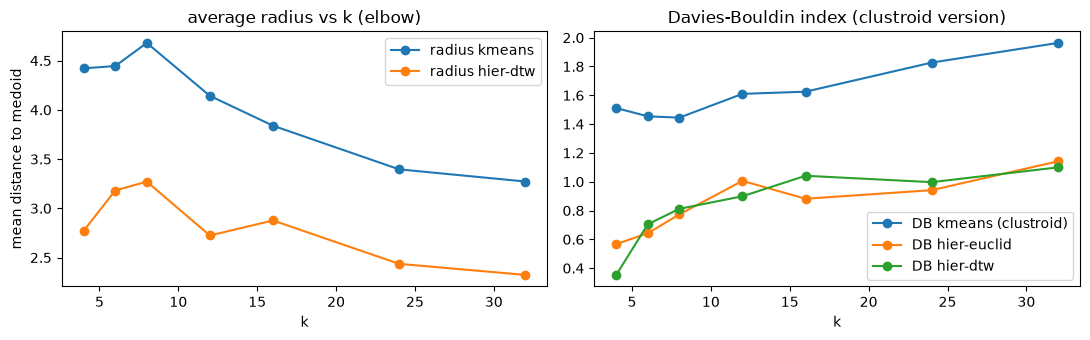

In [17]:
fig, axs = plt.subplots(ncols=2, figsize=(11, 3.5))
general[['radius kmeans', 'radius hier-dtw']].plot(ax=axs[0], marker='o')
axs[0].set_title('average radius vs k (elbow)'); axs[0].set_ylabel('mean distance to medoid')
general[['DB kmeans (clustroid)', 'DB hier-euclid', 'DB hier-dtw']].plot(ax=axs[1], marker='o')
axs[1].set_title('Davies-Bouldin index (clustroid version)')
plt.tight_layout()
plt.show()

Note: average linkage tends to produce one very large cluster plus small clusters of unusual days (see `largest cluster`).
For representative days this is not necessarily bad (extreme days get their own representative), but it is checked against the task metrics in Part 7.

### Part 6: Graph clustering

Days are nodes. Every day is connected to its `K_NN` nearest days (union, so the graph is undirected), with weight
$w_{ij} = \exp\!\big(-d_{ij}^2/(2\sigma^2)\big)$, where $\sigma$ is the median of the kNN distances.
The graph only needs pairwise distances, so it works with DTW. Only local neighbourhoods are kept, which makes the
partition robust to non-convex cluster shapes and to a few unusual days.

1. **Spectral clustering (own implementation).** Following the lecture (k clusters → use several eigenvectors of a
   normalised Laplacian) and von Luxburg (2007): $L_{sym} = I - D^{-1/2} W D^{-1/2}$, take the eigenvectors of the $k$ smallest eigenvalues,
   normalise the rows and run k-means on them. Here k-means works in the spectral embedding, not on the curves.
   We compare with `SpectralClustering(affinity='precomputed')` from sklearn.
2. **Louvain** (networkx) maximises modularity and decides the number of communities itself. We vary the resolution $\gamma$.
3. **Modularity** as in the lecture: $Q = \frac{1}{2m}\sum_{C}\sum_{v\ne w \in C}\big(A_{vw} - \frac{d_v d_w}{2m}\big)$ with weighted
   degrees. networkx includes the terms $v=w$, so its values are slightly different; both are reported.

In [18]:
def knn_graph(D, k_nn):
    """Symmetric kNN similarity graph with Gaussian weights.

    :param D: nd-array, shape (n, n), distance matrix
    :param k_nn: int, number of neighbours per node
    :return: nd-array W, shape (n, n), weighted adjacency matrix; float sigma
    """
    n = len(D)
    D_off = D + np.diag(np.full(n, np.inf))                 # exclude self loops
    nn_idx = np.argsort(D_off, axis=1)[:, :k_nn]
    rows, cols = np.repeat(np.arange(n), k_nn), nn_idx.ravel()
    d_nn = D[rows, cols]
    sigma = np.median(d_nn[d_nn > 0])
    W = np.zeros((n, n))
    W[rows, cols] = np.exp(-d_nn ** 2 / (2 * sigma ** 2))
    return np.maximum(W, W.T), sigma


def spectral_embedding(W):
    """Eigen-decomposition of the normalised Laplacian L_sym = I - D^-1/2 W D^-1/2 (eigenvalues ascending)."""
    d_inv_sqrt = 1 / np.sqrt(W.sum(axis=1))
    L_sym = np.eye(len(W)) - d_inv_sqrt[:, None] * W * d_inv_sqrt[None, :]
    return np.linalg.eigh(L_sym)


def labels_spectral(evecs, k, seed=RANDOM_STATE):
    """Spectral clustering with k clusters: rows of the first k eigenvectors, normalised, then k-means."""
    U = evecs[:, :k]
    U = U / np.linalg.norm(U, axis=1, keepdims=True)
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(U)


def modularity_lecture(W, labels):
    """Weighted modularity as defined in the lecture (sum over v != w)."""
    deg = W.sum(axis=1)
    two_m = W.sum()
    Q = 0.0
    for c in np.unique(labels):
        idx = labels == c
        within = W[np.ix_(idx, idx)].sum() - np.trace(W[np.ix_(idx, idx)])
        dd = deg[idx]
        Q += within - (dd.sum() ** 2 - np.sum(dd ** 2)) / two_m
    return Q / two_m


def communities_to_labels(comms, n):
    labels = np.empty(n, dtype=int)
    for c, nodes in enumerate(comms):
        labels[list(nodes)] = c
    return labels

sigma euclid = 2.450, sigma dtw = 2.154
nodes = 1453, edges = 10242, connected components = 1


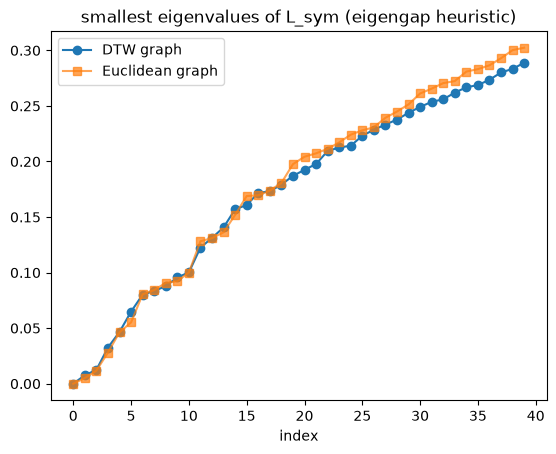

In [19]:
W_euc, sig_euc = knn_graph(D_euc_tr, K_NN)
W_dtw, sig_dtw = knn_graph(D_dtw_tr, K_NN)
G_dtw = nx.from_numpy_array(W_dtw)

#sanity check: the graph should be connected, otherwise spectral clustering returns the components
print(f'sigma euclid = {sig_euc:.3f}, sigma dtw = {sig_dtw:.3f}')
print(f'nodes = {G_dtw.number_of_nodes()}, edges = {G_dtw.number_of_edges()}, '
      f'connected components = {nx.number_connected_components(G_dtw)}')

evals_euc, evecs_euc = spectral_embedding(W_euc)
evals_dtw, evecs_dtw = spectral_embedding(W_dtw)

plt.plot(evals_dtw[:40], 'o-', label='DTW graph')
plt.plot(evals_euc[:40], 's-', label='Euclidean graph', alpha=0.7)
plt.title('smallest eigenvalues of L_sym (eigengap heuristic)'); plt.xlabel('index'); plt.legend()
plt.show()

In [20]:
# compare our spectral clustering with sklearn on the same graph
for k in [4, 8, 12]:
    ours = labels_spectral(evecs_dtw, k)
    sk = SpectralClustering(n_clusters=k, affinity='precomputed', random_state=RANDOM_STATE).fit_predict(W_dtw)
    print(f'k={k:2d}: ARI(ours, sklearn) = {adjusted_rand_score(ours, sk):.3f}, '
          f'modularity ours = {modularity_lecture(W_dtw, ours):.3f}, sklearn = {modularity_lecture(W_dtw, sk):.3f}')

k= 4: ARI(ours, sklearn) = 0.546, modularity ours = 0.635, sklearn = 0.520
k= 8: ARI(ours, sklearn) = 0.626, modularity ours = 0.673, sklearn = 0.670
k=12: ARI(ours, sklearn) = 0.715, modularity ours = 0.699, sklearn = 0.704


In [21]:
# Louvain: number of communities and modularity for different resolutions
rows = []
for gamma in [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]:
    comms = louvain_communities(G_dtw, weight='weight', resolution=gamma, seed=RANDOM_STATE)
    lab = communities_to_labels(comms, G_dtw.number_of_nodes())
    reps, w, m_in, m_out = assess(lab, D_dtw)
    rows.append({'resolution': gamma, 'communities': len(comms),
                 'Q lecture': modularity_lecture(W_dtw, lab),
                 'Q networkx': nx_modularity(G_dtw, comms, weight='weight'),
                 **{f'in_{a}': b for a, b in m_in.items()}, **{f'out_{a}': b for a, b in m_out.items()}})
louvain = pd.DataFrame(rows).set_index('resolution')
louvain.round(3)

,communities,Q lecture,Q networkx,in_energy_err,in_duration_nrmse,in_ramp_nrmse,in_vf_err,in_value_err,out_energy_err,out_duration_nrmse,out_ramp_nrmse,out_vf_err,out_value_err
resolution,,,,,,,,,,,,,
0.5,8,0.696,0.695,0.065,0.053,0.011,0.029,0.038,0.078,0.044,0.020,0.086,0.157
1.0,13,0.715,0.714,0.013,0.033,0.012,0.018,0.030,0.057,0.038,0.022,0.040,0.095
1.5,16,0.709,0.709,0.038,0.031,0.014,0.018,0.056,0.089,0.042,0.025,0.039,0.125
2.0,20,0.703,0.702,0.039,0.031,0.010,0.029,0.067,0.084,0.043,0.018,0.007,0.090
3.0,29,0.676,0.676,0.022,0.020,0.007,0.025,0.046,0.052,0.032,0.012,0.054,0.104
4.0,41,0.642,0.641,0.013,0.019,0.007,0.026,0.039,0.041,0.025,0.010,0.044,0.083


### Part 7: Main experiment — error vs. number of representative days

The 2×2 design separates the two effects:

| | Euclidean distance | DTW distance |
|---|---|---|
| point-based partition | k-means, hierarchical | hierarchical |
| graph partition | spectral | spectral (+ Louvain from Part 6) |

Comparing columns isolates the effect of DTW; comparing rows isolates the effect of the graph.

k-means and spectral clustering depend on a random initialisation, so they are repeated with `N_SEEDS` seeds.
The plots show the mean over the seeds (line) and the 10–90 % range (coloured band). Hierarchical clustering is
deterministic and run once. The grey band is the 5–95 % range of the random baseline.

In [22]:
# method: (clustering function of (k, seed), distance matrix, stochastic?)
METHODS = {
    'kmeans-euclid':   (lambda k, s: labels_kmeans(k, s),                  D_euc, True),
    'hier-euclid':     (lambda k, s: labels_hierarchical(k, D_euc_tr),     D_euc, False),
    'hier-dtw':        (lambda k, s: labels_hierarchical(k, D_dtw_tr),     D_dtw, False),
    'spectral-euclid': (lambda k, s: labels_spectral(evecs_euc, k, s),     D_euc, True),
    'spectral-dtw':    (lambda k, s: labels_spectral(evecs_dtw, k, s),     D_dtw, True),
}
SEEDS = list(range(RANDOM_STATE, RANDOM_STATE + N_SEEDS))

t0 = time.time()
rows = []
for name, (cluster, D, stochastic) in METHODS.items():
    for k in K_LIST:
        for seed in (SEEDS if stochastic else [RANDOM_STATE]):
            labels = cluster(k, seed)
            reps, w, m_in, m_out = assess(labels, D)
            rows.append({'method': name, 'k': k, 'seed': seed,
                         **{f'in_{a}': b for a, b in m_in.items()}, **{f'out_{a}': b for a, b in m_out.items()}})
results = pd.DataFrame(rows)
metric_cols = [c for c in results.columns if c.startswith(('in_', 'out_'))]
print(f'{len(results)} runs in {time.time() - t0:.1f} s')

# mean over the seeds for every method and k
res_mean = results.groupby(['method', 'k'])[metric_cols].mean().reset_index()

baseline = pd.concat([random_baseline(k, D_euc).assign(k=k) for k in K_LIST])
res_mean.round(3).head(10)

224 runs in 36.3 s


,method,k,in_energy_err,in_duration_nrmse,in_ramp_nrmse,in_vf_err,in_value_err,out_energy_err,out_duration_nrmse,out_ramp_nrmse,out_vf_err,out_value_err
0,hier-dtw,4,0.189,0.202,0.021,0.258,0.021,0.184,0.197,0.031,0.192,0.027
1,hier-dtw,6,0.209,0.200,0.020,0.275,0.009,0.230,0.192,0.031,0.223,0.058
2,hier-dtw,8,0.060,0.092,0.015,0.109,0.042,0.134,0.094,0.019,0.078,0.066
3,hier-dtw,12,0.058,0.092,0.014,0.141,0.075,0.100,0.092,0.018,0.156,0.040
4,hier-dtw,16,0.046,0.051,0.012,0.012,0.058,0.055,0.059,0.020,0.020,0.036
5,hier-dtw,24,0.035,0.029,0.012,0.058,0.091,0.034,0.025,0.016,0.043,0.075
6,hier-dtw,32,0.056,0.032,0.012,0.060,0.112,0.034,0.026,0.014,0.062,0.094
7,hier-euclid,4,0.209,0.220,0.025,0.154,0.088,0.204,0.215,0.037,0.091,0.131
8,hier-euclid,6,0.208,0.220,0.025,0.156,0.084,0.207,0.214,0.037,0.115,0.115
9,hier-euclid,8,0.116,0.092,0.024,0.020,0.098,0.080,0.092,0.036,0.050,0.126


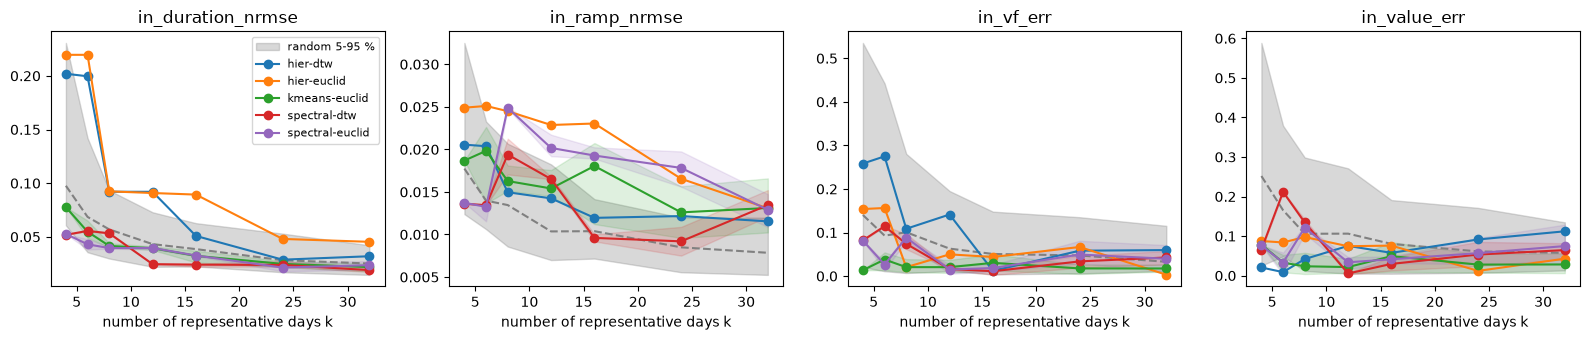

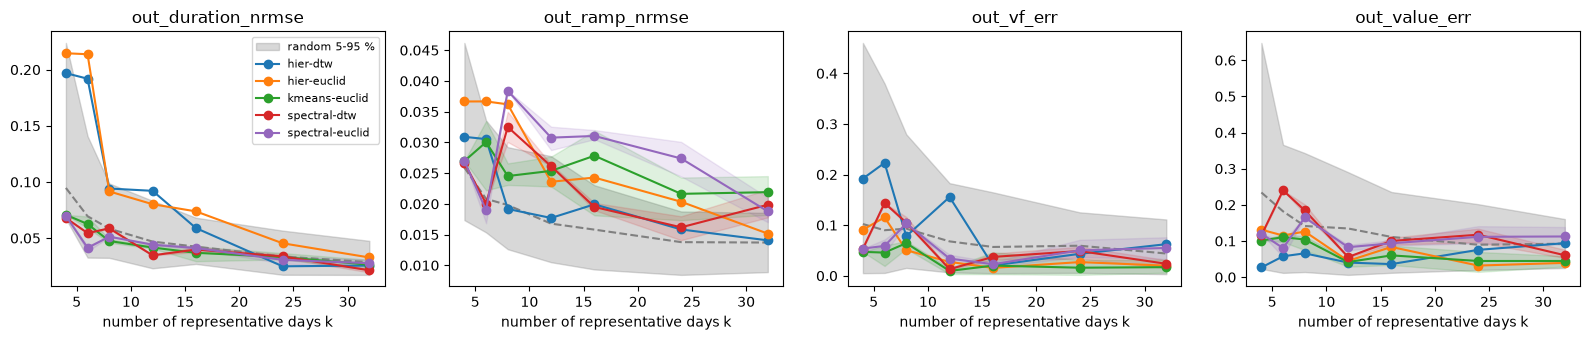

In [23]:
def plot_error_vs_k(prefix, metrics):
    fig, axs = plt.subplots(ncols=len(metrics), figsize=(4 * len(metrics), 3.5))
    for ax, m in zip(axs, metrics):
        col = f'{prefix}_{m}'
        q = baseline.groupby('k')[col].quantile([0.05, 0.5, 0.95]).unstack()
        ax.fill_between(q.index, q[0.05], q[0.95], color='grey', alpha=0.3, label='random 5-95 %')
        ax.plot(q.index, q[0.5], color='grey', ls='--')
        for name, grp in results.groupby('method'):
            stats = grp.groupby('k')[col].agg(['mean', lambda x: x.quantile(0.1), lambda x: x.quantile(0.9)])
            stats.columns = ['mean', 'q10', 'q90']
            line, = ax.plot(stats.index, stats['mean'], marker='o', label=name)
            if grp['seed'].nunique() > 1:        # band only for the stochastic methods
                ax.fill_between(stats.index, stats['q10'], stats['q90'], color=line.get_color(), alpha=0.15)
        ax.set_title(col); ax.set_xlabel('number of representative days k')
    axs[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

plot_error_vs_k('in',  ['duration_nrmse', 'ramp_nrmse', 'vf_err', 'value_err'])
plot_error_vs_k('out', ['duration_nrmse', 'ramp_nrmse', 'vf_err', 'value_err'])

In [24]:
# how often does each method (mean over seeds) beat the median of the random baseline?
med = baseline.groupby('k').median()
beats = res_mean.set_index(['method', 'k'])[metric_cols].lt(med[metric_cols], level='k')
beats.groupby('method').mean().round(2)

,in_energy_err,in_duration_nrmse,in_ramp_nrmse,in_vf_err,in_value_err,out_energy_err,out_duration_nrmse,out_ramp_nrmse,out_vf_err,out_value_err
method,,,,,,,,,,
hier-dtw,0.43,0.0,0.00,0.14,0.71,0.43,0.29,0.14,0.43,0.86
hier-euclid,0.00,0.0,0.00,0.57,1.00,0.43,0.00,0.00,0.86,1.00
kmeans-euclid,1.00,1.0,0.00,1.00,1.00,1.00,1.00,0.00,1.00,1.00
spectral-dtw,0.71,1.0,0.43,0.71,0.57,0.57,0.71,0.14,0.71,0.57
spectral-euclid,0.86,1.0,0.29,0.71,0.71,0.57,1.00,0.14,0.71,0.57


In [25]:
# stability over the seeds: mean pairwise ARI between the partitions of different seeds (1 = identical)
from itertools import combinations
rows = []
for name, (cluster, D, stochastic) in METHODS.items():
    if not stochastic:
        continue
    for k in [6, K_FIX, 24]:
        labs = [cluster(k, s) for s in SEEDS]
        ari = [adjusted_rand_score(a, b) for a, b in combinations(labs, 2)]
        rows.append({'method': name, 'k': k, 'mean ARI': np.mean(ari), 'min ARI': np.min(ari)})
pd.DataFrame(rows).pivot(index='method', columns='k', values='mean ARI').round(2)

k,6,12,24
method,,,
kmeans-euclid,0.93,0.81,0.52
spectral-dtw,1.00,0.98,0.81
spectral-euclid,0.95,0.90,0.83


### Part 8: Sensitivity analysis

Results should not depend on one arbitrary parameter choice. At a fixed $k$ we vary
- the DTW radius $r \in \{0,1,2,3\}$ ($r=0$ is Euclidean, the control),
- the neighbourhood size of the graph `K_NN` $\in \{5,10,15\}$,
- the channels: wind only vs. wind + price.

Stability between parameter settings is measured with the adjusted Rand index (ARI) of the partitions.

In [26]:
K_FIX = 12
rows, parts = [], {}
for features in [['wind'], ['wind', 'price']]:
    for radius in [0, 1, 2, 3]:
        D = distance_matrix(features, radius)
        D_tr = D[np.ix_(train, train)]
        for k_nn in [5, 10, 15]:
            W, _ = knn_graph(D_tr, k_nn)
            _, evecs = spectral_embedding(W)
            lab = labels_spectral(evecs, K_FIX)
            parts[('+'.join(features), radius, k_nn)] = lab
            _, _, m_in, m_out = assess(lab, D)
            rows.append({'features': '+'.join(features), 'radius': radius, 'k_nn': k_nn,
                         'Q lecture': modularity_lecture(W, lab),
                         **{f'in_{a}': b for a, b in m_in.items()}, **{f'out_{a}': b for a, b in m_out.items()}})
sensitivity = pd.DataFrame(rows)
sensitivity.round(3)

,features,radius,k_nn,Q lecture,in_energy_err,in_duration_nrmse,in_ramp_nrmse,in_vf_err,in_value_err,out_energy_err,out_duration_nrmse,out_ramp_nrmse,out_vf_err,out_value_err
0,wind,0,5,0.788,0.005,0.030,0.023,0.187,0.181,0.017,0.030,0.033,0.069,0.050
1,wind,0,10,0.745,0.010,0.035,0.022,0.117,0.107,0.023,0.037,0.033,0.039,0.015
2,wind,0,15,0.726,0.000,0.029,0.024,0.104,0.104,0.028,0.032,0.035,0.013,0.015
3,wind,1,5,0.796,0.038,0.027,0.013,0.075,0.034,0.047,0.029,0.020,0.004,0.050
4,wind,1,10,0.748,0.003,0.025,0.021,0.089,0.085,0.016,0.026,0.030,0.021,0.005
5,wind,1,15,0.727,0.019,0.032,0.022,0.154,0.133,0.027,0.036,0.031,0.083,0.053
6,wind,2,5,0.788,0.002,0.019,0.016,0.035,0.033,0.029,0.024,0.025,0.049,0.077
7,wind,2,10,0.749,0.004,0.019,0.015,0.063,0.059,0.025,0.024,0.023,0.004,0.022
8,wind,2,15,0.728,0.014,0.017,0.010,0.007,0.021,0.013,0.015,0.018,0.043,0.055
9,wind,3,5,0.789,0.027,0.021,0.010,0.050,0.076,0.038,0.025,0.016,0.129,0.162


In [27]:
# stability: ARI between the main setting and every other setting
main = parts[('wind+price', DTW_RADIUS, K_NN)]
sensitivity['ARI vs main'] = [adjusted_rand_score(main, parts[(f, r, kn)])
                              for f, r, kn in zip(sensitivity['features'], sensitivity['radius'], sensitivity['k_nn'])]
sensitivity.pivot_table(index=['features', 'radius'], columns='k_nn', values='ARI vs main').round(2)

k_nn                 5     10    15
features   radius                  
wind       0       0.24  0.25  0.26
           1       0.25  0.26  0.25
           2       0.26  0.26  0.26
           3       0.25  0.26  0.26
wind+price 0       0.57  0.67  0.60
           1       0.56  0.80  0.74
           2       0.76  1.00  0.80
           3       0.62  0.76  0.80

### Part 9: Interpretation of the representative days

For the selected method we plot the representative days (bold) on top of their cluster members, with the weight
(number of days) and the month distribution of each cluster. This checks whether the clusters are physically meaningful
(e.g. calm days, windy days, ramp-up and ramp-down days, windy days with low prices) or only driven by the season.

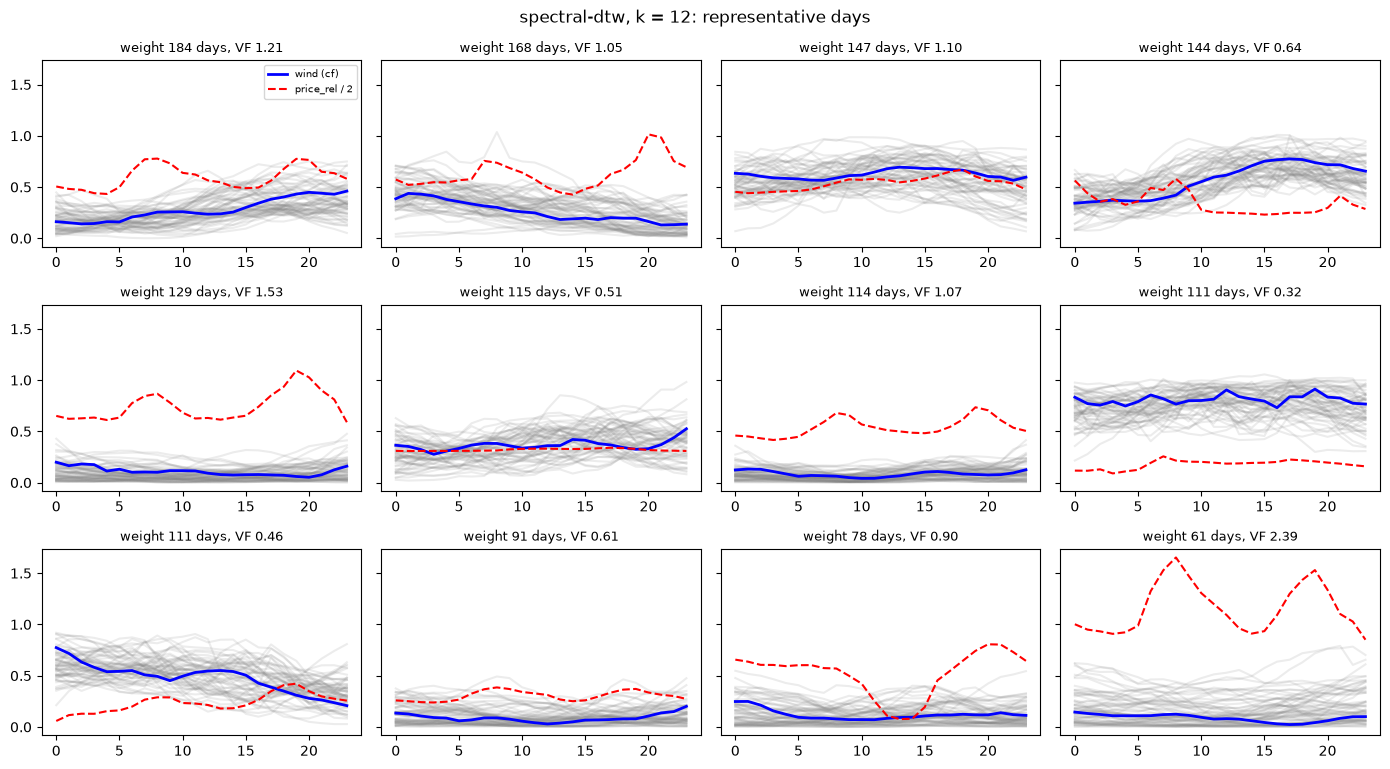

In [28]:
best_name = 'spectral-dtw'
cluster, D, _ = METHODS[best_name]
labels = cluster(K_FIX, RANDOM_STATE)
reps, w, m_in, m_out = assess(labels, D)
cf_tr, pr_tr = CF[train], PREL[train]
order = np.argsort(-w)

ncols = 4
nrows = int(np.ceil(len(reps) / ncols))
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 2.6 * nrows), sharey=True)
for ax, c in zip(axs.flatten(), order):
    members = np.where(labels == np.unique(labels)[c])[0]
    for i in members[:60]:
        ax.plot(cf_tr[i], color='grey', alpha=0.15)
    ax.plot(cf_tr[reps[c]], color='b', lw=2, label='wind (cf)')
    ax.plot(pr_tr[reps[c]] / 2, color='r', lw=1.5, ls='--', label='price_rel / 2')
    ax.set_title(f'weight {w[c]} days, VF {value_factor(cf_tr[members], pr_tr[members]):.2f}', fontsize=9)
axs.flatten()[0].legend(fontsize=7)
plt.suptitle(f'{best_name}, k = {K_FIX}: representative days')
plt.tight_layout()
plt.show()

years of the representative days: {2021: 4, 2022: 3, 2023: 2, 2024: 3}


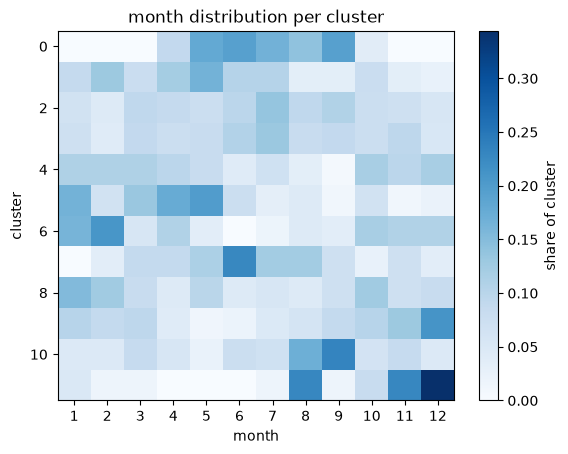

In [29]:
# which years do the representative days come from? (a strong bias towards one year would be a warning sign)
print('years of the representative days:', pd.Series(days['year'].values[train][reps]).value_counts().sort_index().to_dict())

# month distribution per cluster
months = days['month'].values[train]
table = pd.crosstab(labels, months, normalize='index')
plt.imshow(table.values, aspect='auto', cmap='Blues')
plt.colorbar(label='share of cluster')
plt.xticks(range(12), range(1, 13)); plt.xlabel('month'); plt.ylabel('cluster')
plt.title('month distribution per cluster')
plt.show()

### Part 10: Summary and group contributions

The tables collect the main numbers for the report: for every method the metrics at `K_FIX` representative days,
in-sample (2021–2024) and out-of-sample (2025), as mean over the seeds next to the median of the random baseline,
plus the standard deviation over the seeds.

In [30]:
# mean (and standard deviation over the seeds) at K_FIX representative days
at_k = results[results['k'] == K_FIX]
summary = at_k.groupby('method')[metric_cols].mean().reindex(list(METHODS))
summary.loc['random (median)'] = baseline[baseline['k'] == K_FIX][metric_cols].median()
summary_std = at_k.groupby('method')[metric_cols].std().reindex(list(METHODS))   # NaN for deterministic methods
print('mean over seeds'); display(summary.round(3))
print('standard deviation over seeds'); display(summary_std.round(3))

mean over seeds


,in_energy_err,in_duration_nrmse,in_ramp_nrmse,in_vf_err,in_value_err,out_energy_err,out_duration_nrmse,out_ramp_nrmse,out_vf_err,out_value_err
method,,,,,,,,,,
kmeans-euclid,0.032,0.039,0.015,0.021,0.022,0.035,0.042,0.025,0.010,0.042
hier-euclid,0.118,0.091,0.023,0.050,0.074,0.070,0.080,0.024,0.027,0.045
hier-dtw,0.058,0.092,0.014,0.141,0.075,0.100,0.092,0.018,0.156,0.040
spectral-euclid,0.048,0.040,0.020,0.015,0.034,0.051,0.044,0.031,0.034,0.083
spectral-dtw,0.011,0.025,0.017,0.016,0.005,0.043,0.035,0.026,0.013,0.056
random (median),0.060,0.043,0.010,0.063,0.106,0.076,0.047,0.017,0.068,0.135


standard deviation over seeds


,in_energy_err,in_duration_nrmse,in_ramp_nrmse,in_vf_err,in_value_err,out_energy_err,out_duration_nrmse,out_ramp_nrmse,out_vf_err,out_value_err
method,,,,,,,,,,
kmeans-euclid,0.011,0.002,0.001,0.018,0.017,0.003,0.001,0.002,0.006,0.010
hier-euclid,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hier-dtw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spectral-euclid,0.007,0.001,0.002,0.009,0.015,0.007,0.001,0.002,0.007,0.008
spectral-dtw,0.003,0.000,0.001,0.004,0.002,0.000,0.000,0.001,0.004,0.003


**Group contributions**

| Member (name, student number) | Main contributions |
|---|---|
| ... | data download and preprocessing (Parts 1–2) |
| ... | DTW implementation and validation (Part 3) |
| ... | general clustering and evaluation framework (Parts 4–5) |
| ... | graph clustering, experiments and interpretation (Parts 6–9) |